In [1]:
import math
pi = math.pi
import numpy as np
# Suppress warnings
import warnings
warnings.filterwarnings('ignore')
import matplotlib.pyplot as plt
%matplotlib inline
import matplotlib
#matplotlib.rcParams.update({'font.size': 24, 'text.usetex': True})
# Integration
import scipy.integrate as integrate
from scipy.integrate import simpson
from qutip import *
# from scipy.integrate import cumulative_trapezoid
from scipy.interpolate import interp1d
from scipy.linalg import pinv

### Quantum Dots' Parametrs

$ɛ = 0$ On-site local energy


$Ω=10$ Intra-reservoir tunnelling energy/hopping amplitude

### Basis Energies

$E = 0$

### Reservoirs' parameters

$T = 0.2 - 2 $ Temperature

$\mu = 0.0$ Electrochemical potential of the left reservoir

In [2]:
# Quantum Dots' Parametrs
eps = 0.0 # on-site mean local energy
Gamma = 1.0 # the overall frequency scale of the dissipative dynamics
Omega = 1.0 # intra-reservoir tunnelling energy/hopping amplitude
# Basis Energies
E = 0.0 
T = np.linspace(0.0, 10, 101)#np.array([0,np.inf])#np.linspace(0.0, 100,  101) #np.inf,
mu = 0.0
# Hamiltonian
H = E * sigmam().dag() * sigmam() 
# Total particle number operator
N = sigmam().dag() * sigmam()
#Thermal State of the system
# rho0 = []
# for i in range(len(T)):
#     Z = ((-(H-mu*N)/T[i]).expm()).tr()
#     rho0.append((-H/T[i]).expm()/Z)
rho0 = rand_dm(2)

### Fermi-Dirac fucntion

\begin{equation*}
f(\omega) = \frac{1}{e^{β(\omega-\mu)}+1}
\end{equation*}

### Spectral density

\begin{align*}
\mathcal{J}_N(\omega) = \frac{\Gamma}{2\pi} \sqrt{1 - \frac{\omega^2}{\Omega^2}} \, \Theta(\Omega - |\omega|)
\end{align*}
### Propability Destribution of Excitation Energy

if $\Gamma = \Omega$ 
\begin{align*}
\varphi(\omega)=\frac{4\mathcal{J}_{\mathrm{N}}(\omega)}{\Omega^2}
\end{align*}
else:
\begin{align*}
\varphi(\omega)=\frac{1}{1-\Gamma / \Omega} \frac{\mathcal{J}_{\mathrm{N}}(\omega)}{\left(\omega-E^{\prime}\right)^2+\Gamma^2 / 4}
\end{align*}
### Shifted Energies and Decay Rates

\begin{align*}
E' = \frac{1 - \Gamma / 2\Omega}{1 - \Gamma / \Omega} E, \quad
\Gamma' = \frac{\sqrt{1 - \Gamma / \Omega - E^2 / \Omega^2}}{1 - \Gamma / \Omega} \Gamma.
\end{align*}

### Noise kernel: $\Phi$

\begin{equation*}
\Phi(t) = \int \mathrm{d}\omega\, e^{-i\omega t}\, \mathcal{J}(\omega) f(\omega)
\end{equation*}


### The propagator

\begin{equation*}
G(t) = \int \mathrm{d}\omega\, e^{-i\omega t}\ \varphi(\omega)
\end{equation*}

### Matrix for the loss rate

\begin{align*}
\mathrm{i}H(t) + \frac{1}{2}\Gamma(t) &= -G^{-1}\partial_t G 
\end{align*}

\begin{equation*}
\mathrm{i}H(t) = 0.0 
\end{equation*}

\begin{align*}
\Gamma(t) &= -2 \frac{\partial_t G}{G} 
\end{align*}

In [3]:
# dimensionless Fermi-Dirac fucntion
f = lambda x: 1./(1. + np.exp(x))
# Spectral density
def J(omega, Gamma, Omega):
     return Gamma/(2.0*np.pi)*np.sqrt(1.0-omega**2/Omega**2)*np.heaviside(Omega-abs(omega),0)
def phi(omega, Gamma, Omega, E):
    if Gamma == Omega:
        return 4/Omega**2*J(omega, Gamma, Omega)
    else:
        E_dash = (1.0-Gamma/(2.0*Omega))/(1.0-Gamma/Omega)*E
        Gamma_dash = np.sqrt(1.0-Gamma/Omega-(E/Omega)**2)/(1.0-Gamma/Omega)*Gamma
        return (1.0/(1.0-Gamma/Omega))*1.0/((omega-E_dash)**2+(Gamma_dash/2.0)**2)*J(omega, Gamma, Omega)
# Gamma prime
# Gamma_function = lambda Gamma, Omega, E: np.sqrt(1.0-Gamma/Omega-(E/Omega)**2)/(1.0-Gamma/Omega)*Gamma 
def dPhi(omega, t, Gamma, Omega, mu, T):
    if T == 0:
        return np.exp(-1j * omega * t) * J(omega, Gamma, Omega)
    elif T == np.inf:
        return 0.0 
    else:
        return np.exp(-1j * omega * t) * J(omega, Gamma, Omega) * f((omega - mu)/T)
# Define G_dagger (conjugate Green's function time evolution)
def dG_t(omega, Gamma, Omega, E, t):
    # Gamma_val = Gamma_function(Gamma, Omega, E)
    return  np.exp(-1j * omega * t)*phi(omega, Gamma, Omega, E) 
def dG_prime_t(omega, Gamma, Omega, E, t):
    # Gamma_val = Gamma_function(Gamma, Omega, E)
    return  omega*np.exp(-1j * omega * t)*phi(omega, Gamma, Omega, E)

In [4]:
# time 
t = np.linspace(0.0, 3.0, 101)
Phi_t = np.zeros((len(T), len(t)), dtype=complex)
for i, Ti in enumerate(T):
    for j, tj in enumerate(t):
        Phi_t[i, j] = integrate.quad(dPhi, -Omega, Omega, args=(tj, Gamma, Omega, mu, Ti), epsabs=1e-10, epsrel=1e-14, complex_func=True)[0]
G_t = np.zeros((len(T), len(t)), dtype=complex)
for i, Ti in enumerate(T):
    for j, tj in enumerate(t):
        G_t[i, j] = integrate.quad(dG_t, -Omega, Omega, args=(Gamma, Omega, E, tj), epsabs=1e-10, epsrel=1e-14, complex_func=True)[0]
G_prime_t = np.zeros((len(T), len(t)), dtype=complex)
for i, Ti in enumerate(T):
    for j, tj in enumerate(t):
        G_prime_t[i, j] = integrate.quad(dG_prime_t, -Omega, Omega, args=(Gamma, Omega, E, tj), epsabs=1e-10, epsrel=1e-14, complex_func=True)[0]
G_dagger_t = np.conj(G_t) 
Gamma_t = np.real(2*1j*G_prime_t/G_t) # 0 in our case

### Time-dependent Rate Matrices: Gain rate

\begin{equation*}
Z(t)  = \int_0^t \mathrm{d} t'\int_0^t \mathrm{d} t''G^\dagger(t')\Phi(t'-t'')G(t'')
\end{equation*}

\begin{align*}
\Lambda^+ &= \partial_t Z - \mathrm{i} [H, Z] + \frac{1}{2} \{ \Gamma,Z\}\\
\Lambda^-	&= \Gamma - \Lambda^+
\end{align*}

### Time-dependent Rate: Gain rate

\begin{align*}
\Lambda^+(t) &= \partial_t Z(t)  +\Gamma(t) Z(t)
\end{align*}

### Time-dependent Rate: Loss Rate

\begin{equation*}
\Lambda^{-}(t) = \Gamma(t)  - \Lambda^{+}(t)
\end{equation*}

In [5]:
# Allocate Z(T, t) as a 2D array
Z_Tt = np.zeros((len(T), len(t)), dtype=complex)

# For each temperature T index
for i_T, Ti in enumerate(T):
    # print(f"Computing Z(T={Ti:.2f})...")
    # For each final time t[t_idx]
    for t_idx in range(len(t)):
        tmax = t[t_idx]  # integrate from 0 to t[t_idx]

        # Find grid indices for integration variable τ = t' and t''
        t_grid = t[:t_idx+1]          # 0 <= t' <= t[t_idx]
        N = len(t_grid)

        # Slice G_dagger(t'), G(t'') and Phi(t'-t'') on this sub‑grid
        Gd_tprime = G_dagger_t[i_T, :t_idx+1]          # G^\dagger(t')
        G_tprime = G_t[i_T, :t_idx+1]                  # G(t'')

        # Build meshgrid for t' and t''
        t1, t2 = np.meshgrid(t_grid, t_grid, indexing='ij')   # t1[i,j] = t', t2[i,j] = t''

        # Evaluate Phi(t'-t'') on the mesh
        tau = t1 - t2
        # For numerical safety, trim to [-Omega, Omega] in the integrand via Phi_t
        Phi_tau = np.zeros((N, N), dtype=complex)
        for i in range(N):
            for j in range(N):
                istar = np.argmin(np.abs(t - tau[i, j]))
                Phi_tau[i, j] = Phi_t[i_T, istar] if istar < len(Phi_t[i_T]) else 0.0

        # Integrand: K(t',t'') = G^\dagger(t') Phi(t'-t'') G(t'')
        integrand = Gd_tprime[:, None] * Phi_tau * G_tprime[None, :]

        # 2D integral: ∫₀^t dt' ∫₀^t dt'' K(t',t'')
        Z_Tt[i_T, t_idx] = simpson(
            [simpson(integrand[i, :], t_grid) for i in range(N)],
            t_grid)

In [6]:
Z_dot_Tt = np.zeros_like(Z_Tt, dtype=complex)

for i_T in range(len(T)):
    for t_idx in range(len(t)):
        tmax = t[t_idx]
        if t_idx == 0:
            Z_dot_Tt[i_T, t_idx] = 0.0
            continue

        t_grid = t[:t_idx+1]   # 0 <= t'' <= tmax
        N = len(t_grid)

        Gd_t = G_dagger_t[i_T, t_idx]        # G^\dagger(t) at final time t
        G_tprime = G_t[i_T, :t_idx+1]        # G(t'') on subgrid

        # Build tau = t - t''
        tau = tmax - t_grid
        # Interpolate Phi(t-t'') from your precomputed Phi_t (on full t grid)
        Phi_tau = np.zeros(N, dtype=complex)
        for j in range(N):
            istar = np.argmin(np.abs(t - tau[j]))
            if istar < len(Phi_t[i_T]):
                Phi_tau[j] = Phi_t[i_T, istar]
            else:
                Phi_tau[j] = 0.0

        # Integrand: integrand(t'') = G^\dagger(t) * Phi(t-t'') * G(t'')
        integrand = Gd_t * Phi_tau * G_tprime
        Z_dot_Tt[i_T, t_idx] = 2.0 * simpson(integrand, t_grid)

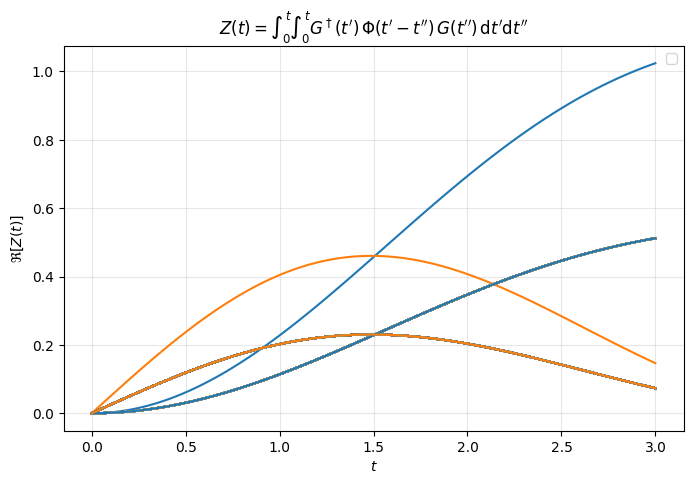

In [7]:
# # --- Plot example: real part of Z(T, t) for each T ---
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 5))
for i_T, Ti in enumerate(T):
    plt.plot(t, np.real(Z_Tt[i_T, :])) #, label=f"T = {Ti:.2f}"
    plt.plot(t, np.real(Z_dot_Tt[i_T, :])) #, label=f"T = {Ti:.2f}"
plt.xlabel(r"$t$")
plt.ylabel(r"$\Re[Z(t)]$")
plt.title(r"$Z(t) = \int_0^t \int_0^t G^\dagger(t')\,\Phi(t'-t'')\,G(t'')\,\mathrm{d}t'\mathrm{d}t''$")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


In [8]:
# Lambda_plus_t = Z_dot_Tt + Gamma_t * Z_Tt
# Lambda_minus_t = Gamma_t - Lambda_plus_t
Lambda_plus_t = np.real(Z_dot_Tt + Gamma_t * Z_Tt)
Lambda_minus_t = np.real(Gamma_t - Lambda_plus_t)

In [ ]:
# rho_t = []
# for i in range(len(T)):

#     L_plus_interp = interp1d(t, Lambda_plus_t[i, :], kind="cubic", bounds_error=False,
#                          fill_value=(Lambda_plus_t[i, 0], Lambda_plus_t[i, -1])) # kind="linear", bounds_error=False, fill_value="extrapolate"
#     L_minus_interp = interp1d(t, Lambda_minus_t[i, :], kind="cubic", bounds_error=False,
#                          fill_value=(Lambda_minus_t[i, 0], Lambda_minus_t[i, -1]))

#     def L_plus(t_val, args=None):
#         #return float(L_plus_interp(t_val))
#         return complex(L_plus_interp(t_val))

#     def L_minus(t_val, args=None):
#         #return float(L_minus_interp(t_val))
#         return complex(L_minus_interp(t_val))

#     c_ops = [[sigmam(), L_minus],[sigmap(), L_plus],]

#     opts = Options(nsteps=10000, atol=1e-8, rtol=1e-6, method="bdf")

#     #sol = mesolve(H, rho0[i], t, c_ops=c_ops, options=opts)
#     sol = mesolve(H, rho0, t, c_ops=c_ops, options=opts)
#     rho_t.append(sol.states)

In [9]:
I = np.identity(2)
X = np.array([[0, 1], [1, 0]])
Y = np.array([[0, -1j], [1j, 0]])
Z = np.array([[1, 0], [0, -1]])

E_t_list = [I, X, -1j * Y, X]

lmbda = np.block([[I, X], [X, -I]]) / 2

def vectorize(A):
	a = A.copy().T.flatten()
	a[[2, 4]] = a[[4, 2]]
	a[[3, 5]] = a[[5, 3]]
	a[[10, 12]] = a[[12, 10]]
	a[[11, 13]] = a[[13, 11]]

	return a

def devectorize(A):
	a = A.copy()

	a[[2, 4]] = a[[4, 2]]
	a[[3, 5]] = a[[5, 3]]
	a[[10, 12]] = a[[12, 10]]
	a[[11, 13]] = a[[13, 11]]

	size = int(np.sqrt(len(a)))
	return a.reshape(size, size)

In [10]:
theta = 0
phi = 0
rho_init_1 = np.array([np.cos(theta / 2), np.exp(1j * phi) * np.sin(theta / 2)])
rho_init_2 = np.array([np.sin(theta / 2), -np.exp(1j * phi) * np.cos(theta / 2)])
bell = 0.5 * np.array([[1, 0, 0, 1],
                       [0, 0, 0, 0],
                       [0, 0, 0, 0],
                       [1, 0, 0, 1]])
tstep = t[1] - t[0]

rho_t_1 = []
rho_t_2 = []
dynamical_map = []
g_list = []
for i in range(len(T)):

	L_plus_interp = interp1d(t, Lambda_plus_t[i, :], kind="cubic", bounds_error=False,
	                         fill_value=(Lambda_plus_t[i, 0], Lambda_plus_t[i, -1])) # kind="linear", bounds_error=False, fill_value="extrapolate"
	L_minus_interp = interp1d(t, Lambda_minus_t[i, :], kind="cubic", bounds_error=False,
	                          fill_value=(Lambda_minus_t[i, 0], Lambda_minus_t[i, -1]))

	def L_plus(t_val, args=None):
		# return complex(L_plus_interp(t_val))
		return float(L_plus_interp(t_val))

	def L_minus(t_val, args=None):
		#return complex(L_minus_interp(t_val))
		return float(L_minus_interp(t_val))
	
	c_ops = [[sigmam(), L_minus],[sigmap(), L_plus],]

	opts = Options(nsteps=10000, atol=1e-8, rtol=1e-6, method="bdf")

	sol = mesolve(H, Qobj(rho_init_1), t, c_ops=c_ops, options=opts)
	rho_t_1.append(sol.states)

	sol = mesolve(H, Qobj(rho_init_2), t, c_ops=c_ops, options=opts)
	rho_t_2.append(sol.states)

	rho_1_list = mesolve(H, Qobj(np.array([[1, 0], [0, 0]])), t, c_ops=c_ops, options=opts)
	rho_2_list = mesolve(H, Qobj(np.array([[0, 1], [0, 0]])), t, c_ops=c_ops, options=opts)
	rho_3_list = mesolve(H, Qobj(np.array([[0, 0], [1, 0]])), t, c_ops=c_ops, options=opts)
	rho_4_list = mesolve(H, Qobj(np.array([[0, 0], [0, 1]])), t, c_ops=c_ops, options=opts)

	chi_list = []
	for rho_1, rho_2, rho_3, rho_4 in zip(rho_1_list.states, rho_2_list.states, rho_3_list.states, rho_4_list.states):
		chi_list.append(lmbda @ np.block([[rho_1.full(), rho_2.full()], [rho_3.full(), rho_4.full()]]) @ lmbda)
	chi_list = np.array(chi_list)

	A_list = []
	for chi in chi_list:
		E_list = []
		d, U = np.linalg.eigh(chi)
		d[d < 0] = 0
		for i in range(len(E_t_list)):
			E_list.append(np.sqrt(d[i]) * sum(U[j, i].conj() * E_t_list[j] for j in range(len(E_t_list))))
		A_list.append(sum(np.kron(E, E.conj()) for E in E_list))

	temp_g = []
	for j in range(len(t) - 1):
		A = A_list[j + 1] @ pinv(A_list[j])
		f = np.sum(np.linalg.svd(devectorize(np.kron(A, np.identity(4)) @ vectorize(bell)), compute_uv=False))
		g = (f - 1) / tstep
		temp_g.append(g)
	g_list.append(temp_g)

	dynamical_map.append(A_list)

In [11]:
pauli_list = np.array([X, Y, Z])
tstep = t[1] - t[0]

LPP_list = []
for i in range(len(T)):
	F_list = []
	for j in range(len(t)):
		F = np.zeros((3, 3), dtype=np.complex128)
		for k, a in enumerate(pauli_list):
			for l, b in enumerate(pauli_list):
				F[k, l] = np.trace(a @ np.reshape(dynamical_map[i][j] @ b.flatten(), (2, 2))) / 2
		F_list.append(F)

	F_det_list = [abs(np.linalg.det(F)) for F in F_list]
	F_det_grad_list = np.gradient(F_det_list, tstep, edge_order=2)
	LPP = simpson(np.clip(F_det_grad_list, a_min=0, a_max=np.inf), dx=tstep)
	LPP_list.append(LPP)

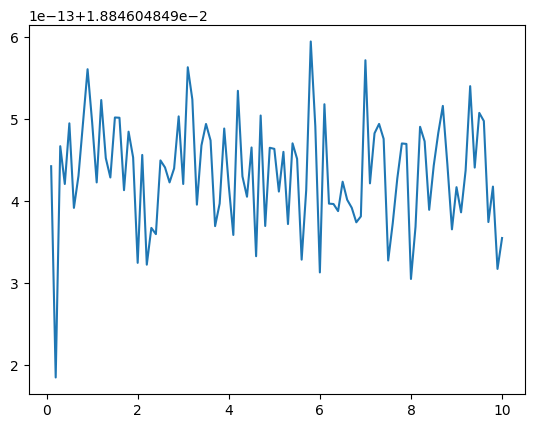

In [12]:
plt.plot(T[1:], LPP_list[1:])

In [13]:
LPP_list

[0.02709729624910885,
 0.018846048492442386,
 0.018846048492184474,
 0.018846048492466846,
 0.0188460484924207,
 0.01884604849249475,
 0.01884604849239155,
 0.018846048492430528,
 0.018846048492495573,
 0.018846048492560816,
 0.01884604849249616,
 0.01884604849242261,
 0.018846048492523186,
 0.01884604849245228,
 0.018846048492428654,
 0.018846048492501894,
 0.01884604849250158,
 0.018846048492413156,
 0.018846048492484557,
 0.01884604849245307,
 0.018846048492324415,
 0.01884604849245617,
 0.018846048492322194,
 0.018846048492367085,
 0.018846048492359487,
 0.0188460484924495,
 0.018846048492440905,
 0.01884604849242264,
 0.018846048492439725,
 0.018846048492503244,
 0.018846048492420688,
 0.01884604849256322,
 0.018846048492523908,
 0.018846048492395483,
 0.018846048492467782,
 0.018846048492493987,
 0.018846048492473875,
 0.018846048492369264,
 0.01884604849239681,
 0.018846048492488415,
 0.01884604849241878,
 0.01884604849235847,
 0.018846048492534448,
 0.018846048492430004,
 0.018

In [14]:
tstep = t[1] - t[0]

BLP_list = []
for i in range(len(T)):
	td_list = [0.5 * np.sum(np.abs(np.linalg.eigvalsh(s1.full() - s2.full()))) for s1, s2 in zip(rho_t_1[i], rho_t_2[i])]
	dtd_list = np.gradient(td_list, tstep, edge_order=2)

	BLP = simpson(np.clip(dtd_list, a_min=0, a_max=np.inf), dx=tstep)
	BLP_list.append(BLP)

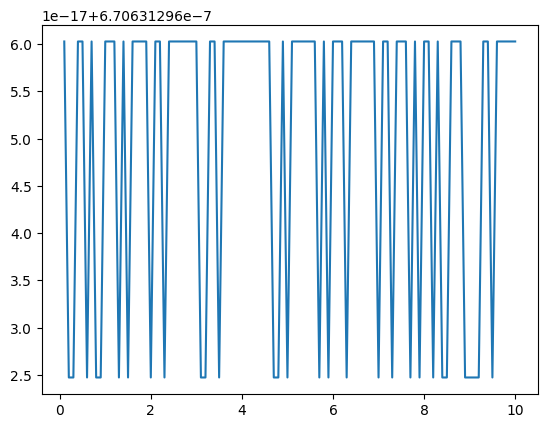

In [15]:
plt.plot(T[1:], BLP_list[1:])

In [16]:
BLP_list

[1.4836840105303395e-06,
 6.706312960602645e-07,
 6.706312960247374e-07,
 6.706312960247374e-07,
 6.706312960602645e-07,
 6.706312960602645e-07,
 6.706312960247374e-07,
 6.706312960602645e-07,
 6.706312960247374e-07,
 6.706312960247374e-07,
 6.706312960602645e-07,
 6.706312960602645e-07,
 6.706312960602645e-07,
 6.706312960247374e-07,
 6.706312960602645e-07,
 6.706312960247374e-07,
 6.706312960602645e-07,
 6.706312960602645e-07,
 6.706312960602645e-07,
 6.706312960602645e-07,
 6.706312960247374e-07,
 6.706312960602645e-07,
 6.706312960602645e-07,
 6.706312960247374e-07,
 6.706312960602645e-07,
 6.706312960602645e-07,
 6.706312960602645e-07,
 6.706312960602645e-07,
 6.706312960602645e-07,
 6.706312960602645e-07,
 6.706312960602645e-07,
 6.706312960247374e-07,
 6.706312960247374e-07,
 6.706312960602645e-07,
 6.706312960602645e-07,
 6.706312960247374e-07,
 6.706312960602645e-07,
 6.706312960602645e-07,
 6.706312960602645e-07,
 6.706312960602645e-07,
 6.706312960602645e-07,
 6.706312960602

In [17]:
RHP_list = []
for i in range(len(T)):
	RHP_list.append(simpson(np.clip(g_list[i], a_min=0, a_max=np.inf), dx=tstep))

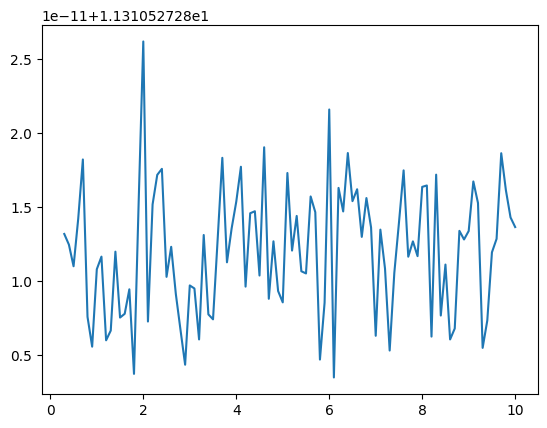

In [18]:
plt.plot(T[3:], RHP_list[3:])

In [19]:
RHP_list[1:]

[11.310527279446205,
 11.310527252746903,
 11.310527279713181,
 11.310527279712456,
 11.310527279710996,
 11.310527279714208,
 11.31052727971822,
 11.310527279707575,
 11.310527279705557,
 11.310527279710795,
 11.310527279711648,
 11.310527279705987,
 11.310527279706646,
 11.310527279711984,
 11.310527279707525,
 11.31052727970778,
 11.310527279709436,
 11.310527279703717,
 11.310527279715291,
 11.310527279726202,
 11.310527279707257,
 11.31052727971518,
 11.310527279717178,
 11.310527279717586,
 11.31052727971028,
 11.31052727971231,
 11.310527279709119,
 11.3105272797067,
 11.310527279704335,
 11.310527279709698,
 11.310527279709493,
 11.310527279706045,
 11.31052727971311,
 11.31052727970774,
 11.310527279707404,
 11.31052727971284,
 11.310527279718332,
 11.310527279711263,
 11.310527279713549,
 11.310527279715366,
 11.310527279717727,
 11.310527279709618,
 11.310527279714583,
 11.310527279714718,
 11.310527279710369,
 11.310527279719045,
 11.310527279708795,
 11.310527279712684,
 1